## Chuẩn bị

In [1]:
from pathlib import Path
import timeit
import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

LAB_DIR = Path.cwd()
if not (LAB_DIR / "gamma_example.png").exists():
    LAB_DIR = LAB_DIR / "lab2"


def read_gray(filename):
    encoded = np.fromfile(LAB_DIR / filename, dtype=np.uint8)
    image = cv2.imdecode(encoded, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(LAB_DIR / filename)
    return image


def to_float01(image):
    return image.astype(np.float32) / 255.0


def to_uint8(image):
    return (np.clip(image, 0.0, 1.0) * 255.0 + 0.5).astype(np.uint8)


def compare_images(images, titles, columns=3, figsize_per_cell=(4.1, 3.5)):
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figsize_per_cell[0] * columns, figsize_per_cell[1] * rows),
        squeeze=False,
    )
    for ax, image, title in zip(axes.ravel(), images, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes.ravel()[len(images):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 1. Gamma correction

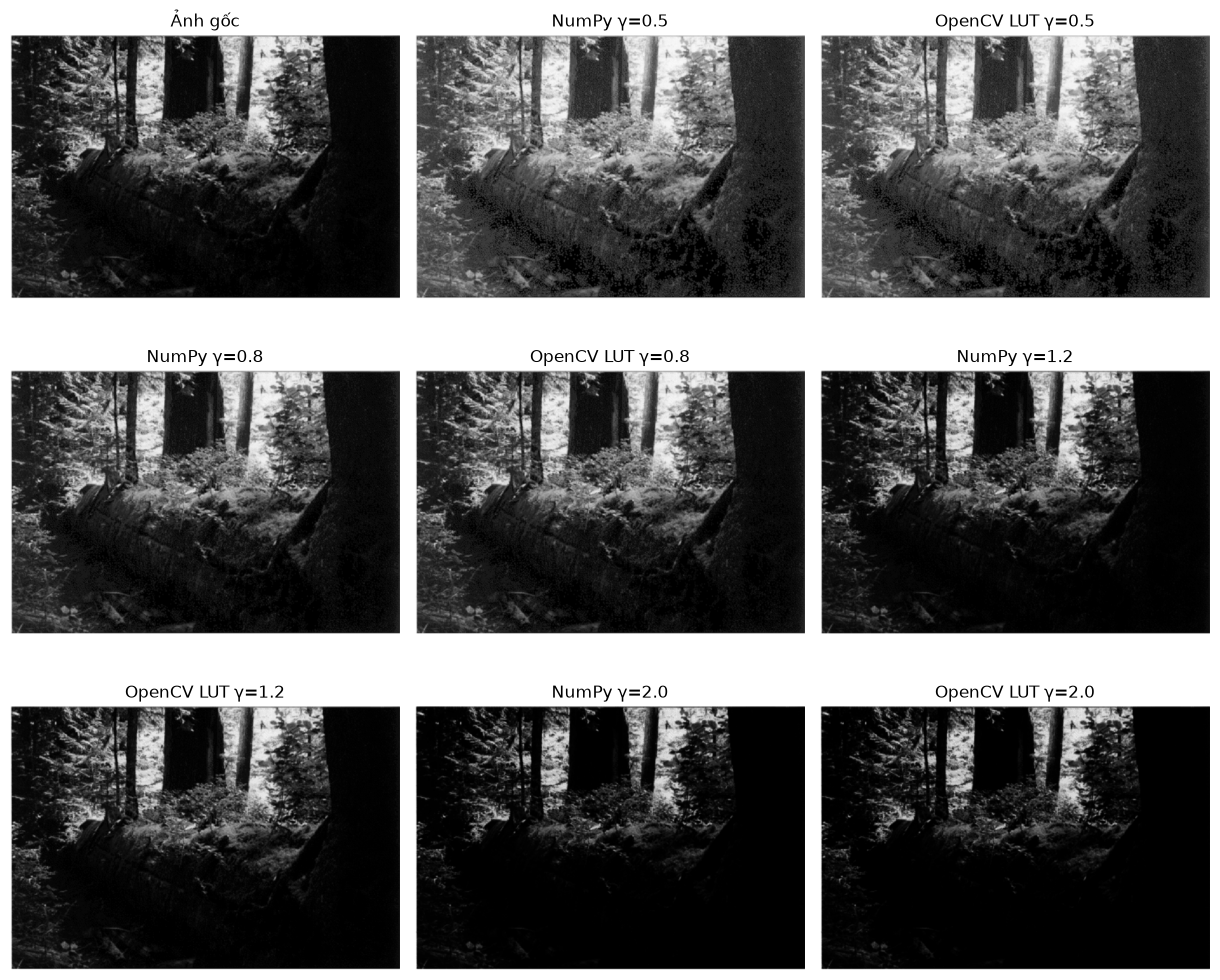

**Nhận xét:** γ < 1 làm sáng rõ nhất các vùng tối; γ > 1 làm ảnh tối hơn. γ=0.5: mean=85.3; NumPy/LUT giống hệt 47.12% pixel; sai khác lớn nhất 1 mức xám. γ=0.8: mean=55.3; NumPy/LUT giống hệt 52.18% pixel; sai khác lớn nhất 1 mức xám. γ=1.2: mean=36.2; NumPy/LUT giống hệt 52.11% pixel; sai khác lớn nhất 1 mức xám. γ=2.0: mean=20.9; NumPy/LUT giống hệt 68.10% pixel; sai khác lớn nhất 1 mức xám.

In [2]:
image_gamma = read_gray("gamma_example.png")

def gamma_numpy(image, gamma):
    if gamma <= 0:
        raise ValueError("gamma phải > 0")
    return to_uint8(to_float01(image) ** gamma)


def gamma_opencv(image, gamma):
    if gamma <= 0:
        raise ValueError("gamma phải > 0")
    lut = np.array([((i / 255.0) ** gamma) * 255.0 for i in range(256)], dtype=np.uint8)
    return cv2.LUT(image, lut)


gamma_values = (0.5, 0.8, 1.2, 2.0)
gamma_images = [image_gamma]
gamma_titles = ["Ảnh gốc"]
gamma_notes = []
for gamma in gamma_values:
    result_np = gamma_numpy(image_gamma, gamma)
    result_cv = gamma_opencv(image_gamma, gamma)
    gamma_images.extend([result_np, result_cv])
    gamma_titles.extend([f"NumPy γ={gamma}", f"OpenCV LUT γ={gamma}"])
    difference = np.abs(result_np.astype(np.int16) - result_cv.astype(np.int16))
    gamma_notes.append(
        f"γ={gamma}: mean={result_np.mean():.1f}; NumPy/LUT giống hệt {np.mean(difference == 0)*100:.2f}% pixel; "
        f"sai khác lớn nhất {difference.max()} mức xám."
    )
compare_images(gamma_images, gamma_titles, columns=3)
display(Markdown("**Nhận xét:** γ < 1 làm sáng rõ nhất các vùng tối; γ > 1 làm ảnh tối hơn. " + " ".join(gamma_notes)))

## 2. Cộng, trừ, nhân, chia hai ảnh

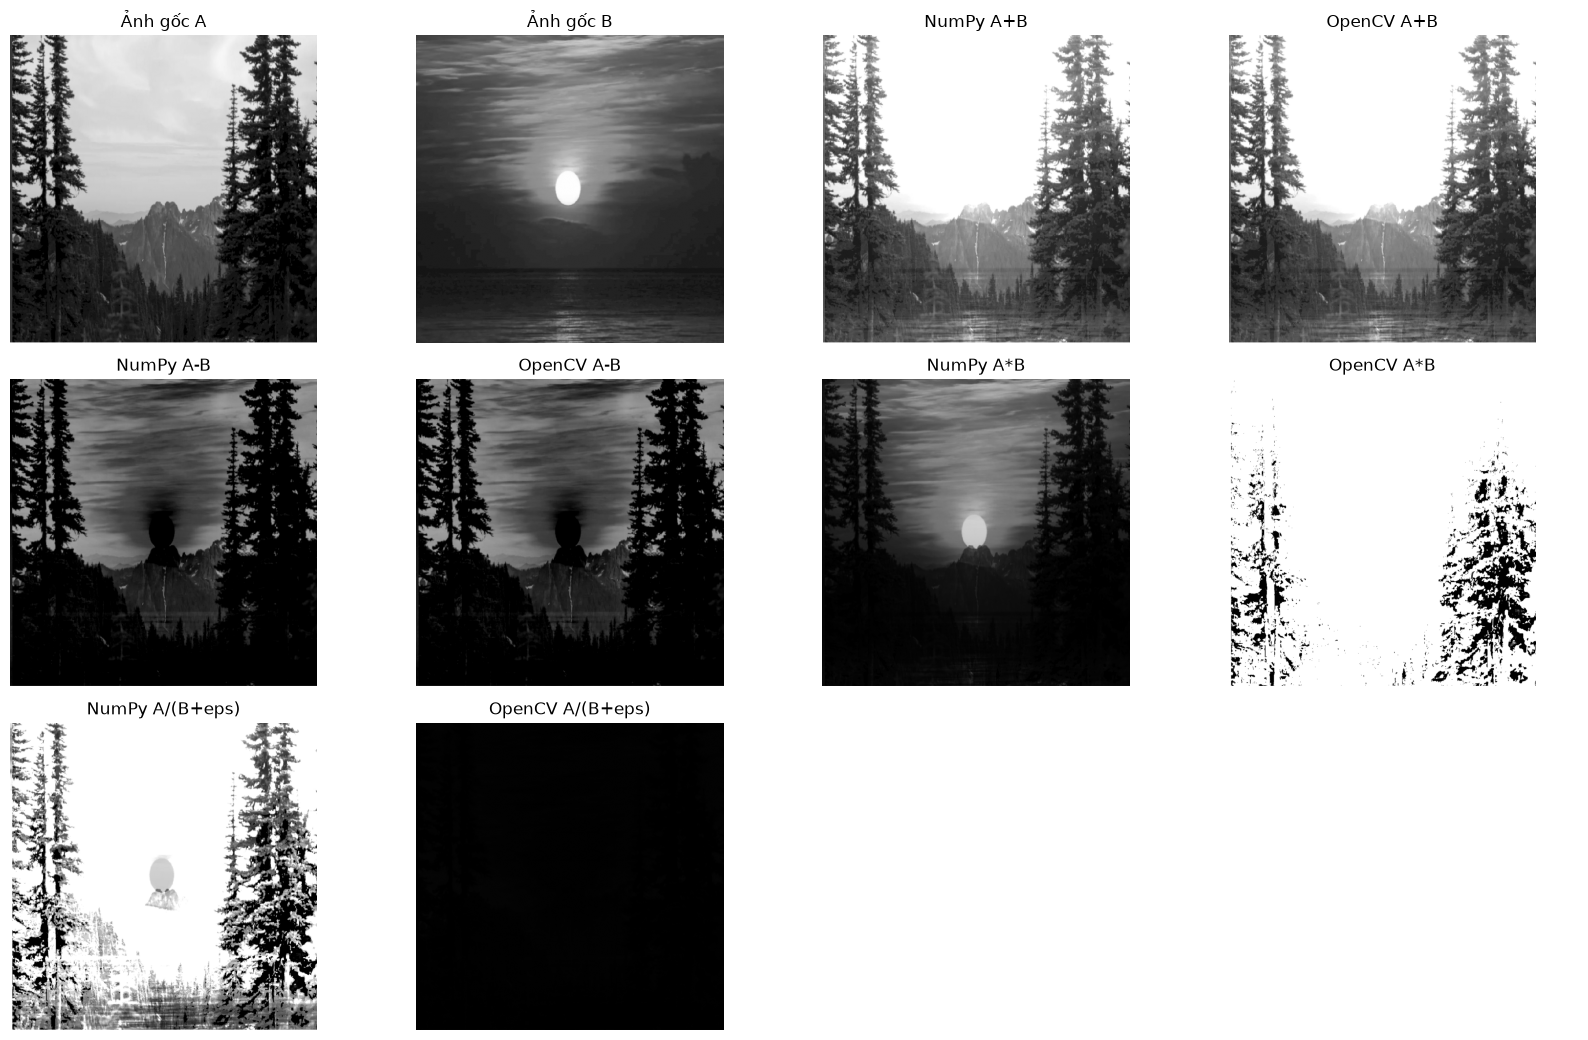

**Nhận xét:** Phép trừ làm nổi khác biệt; để phát hiện thay đổi hai chiều dùng |A−B|. Phép chia nhạy với mẫu số nhỏ, vì vậy cần epsilon/chặn mẫu số. Clipping có thể làm mất độ lớn khi nhiều giá trị vượt 255. Theo đúng ví dụ PDF, NumPy nhân/chia ảnh đã chuẩn hóa còn OpenCV dùng uint8 với scale=1; vì thế hai kết quả có thang đo khác nhau. A+B: NumPy mean=152.5, OpenCV mean=152.5, pixel giống hệt=100.0%. A-B: NumPy mean=41.9, OpenCV mean=41.9, pixel giống hệt=100.0%. A*B: NumPy mean=43.1, OpenCV mean=229.4, pixel giống hệt=10.0%. A/(B+eps): NumPy mean=195.3, OpenCV mean=1.3, pixel giống hệt=10.0%.

In [3]:
image_a, image_b = read_gray("1.png"), read_gray("2.png")
assert image_a.shape == image_b.shape, "A và B phải cùng kích thước"

def arithmetic_numpy(a, b):
    af, bf = to_float01(a), to_float01(b)
    return {
        "A+B": to_uint8(af + bf),
        "A-B": to_uint8(af - bf),
        "A*B": to_uint8(af * bf),
        "A/(B+eps)": to_uint8(af / (bf + 1e-6)),
    }


def arithmetic_opencv(a, b):
    b_safe = np.maximum(b, 1).astype(np.uint8)
    return {
        "A+B": cv2.add(a, b),
        "A-B": cv2.subtract(a, b),
        "A*B": cv2.multiply(a, b, scale=1.0),
        "A/(B+eps)": cv2.divide(a, b_safe, scale=1.0),
    }


arithmetic_np = arithmetic_numpy(image_a, image_b)
arithmetic_cv = arithmetic_opencv(image_a, image_b)
images = [image_a, image_b]
titles = ["Ảnh gốc A", "Ảnh gốc B"]
arithmetic_notes = []
for operation in arithmetic_np:
    result_np, result_cv = arithmetic_np[operation], arithmetic_cv[operation]
    images.extend([result_np, result_cv])
    titles.extend([f"NumPy {operation}", f"OpenCV {operation}"])
    delta = np.abs(result_np.astype(np.int16) - result_cv.astype(np.int16))
    arithmetic_notes.append(
        f"{operation}: NumPy mean={result_np.mean():.1f}, OpenCV mean={result_cv.mean():.1f}, "
        f"pixel giống hệt={np.mean(delta == 0)*100:.1f}%."
    )
compare_images(images, titles, columns=4)
display(Markdown(
    "**Nhận xét:** Phép trừ làm nổi khác biệt; để phát hiện thay đổi hai chiều dùng |A−B|. "
    "Phép chia nhạy với mẫu số nhỏ, vì vậy cần epsilon/chặn mẫu số. Clipping có thể làm mất độ lớn khi nhiều giá trị vượt 255. "
    "Theo đúng ví dụ PDF, NumPy nhân/chia ảnh đã chuẩn hóa còn OpenCV dùng uint8 với scale=1; vì thế hai kết quả có thang đo khác nhau. "
    + " ".join(arithmetic_notes)
))

## 3. Mask nhị phân và phép logic

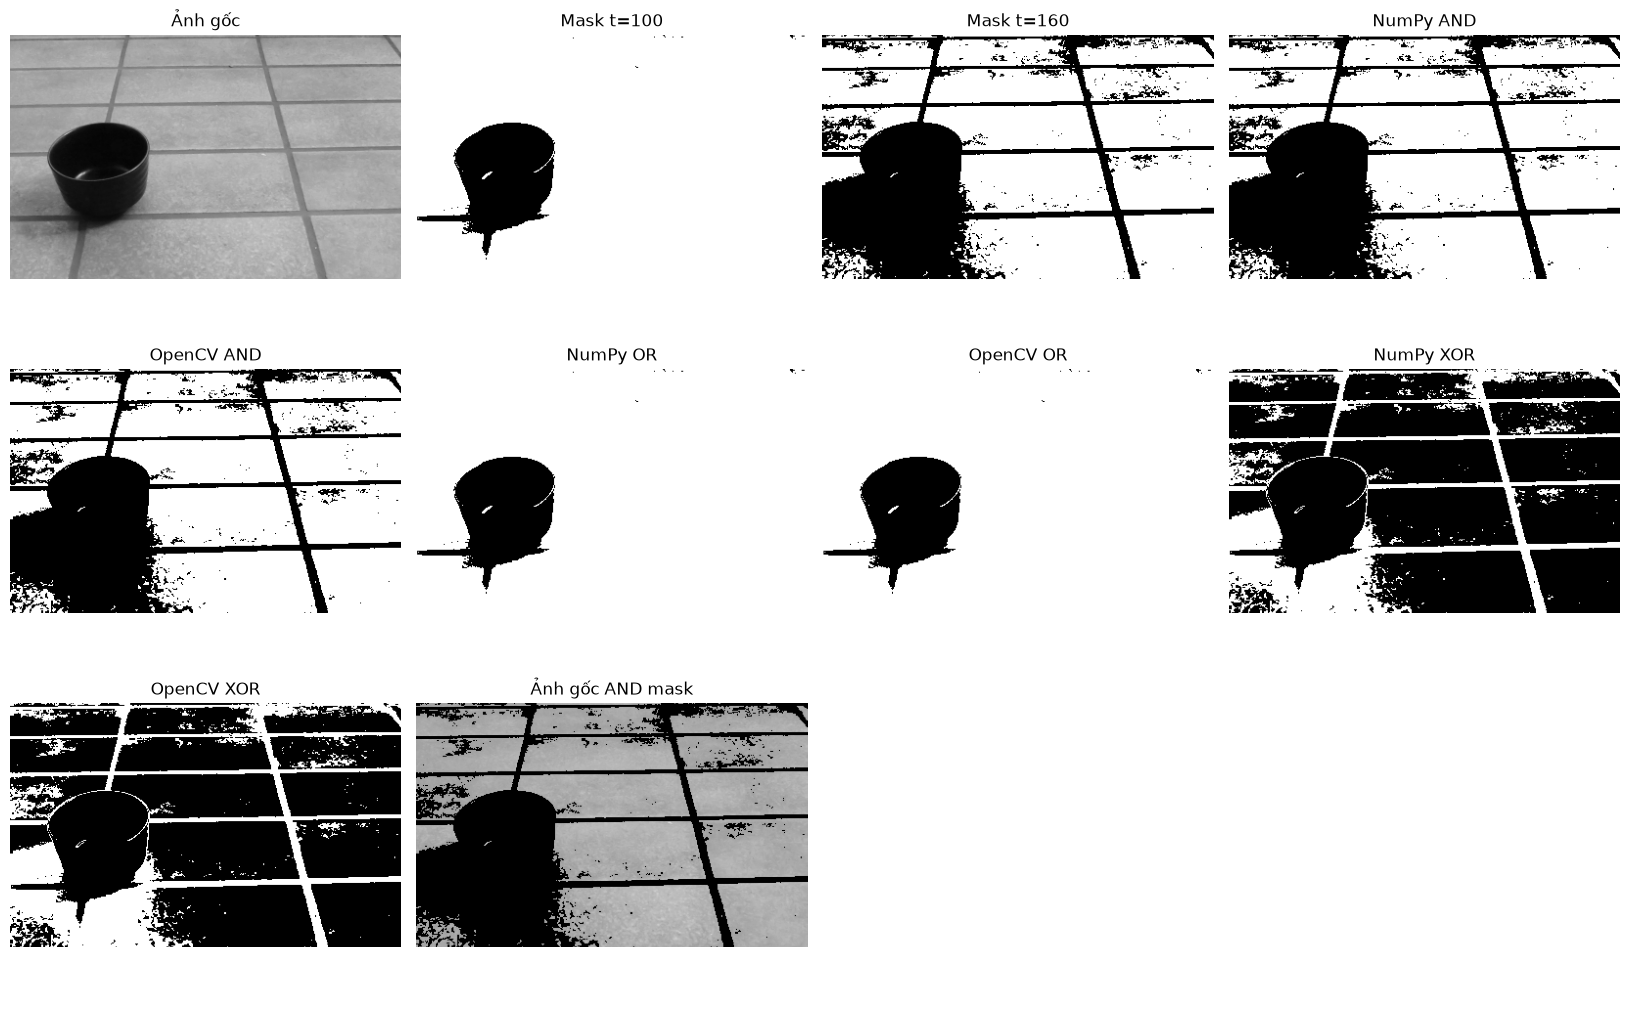

**Nhận xét:** AND giữ pixel chắc chắn được chọn (giao), OR gộp mọi ứng viên (hợp), XOR tìm vùng bất đồng. AND phù hợp với ‘keep only confident pixels’; OR phù hợp với ‘merge all candidates’. AND: hai cách giống nhau 100%; mask giữ 66.7% pixel. OR: hai cách giống nhau 100%; mask giữ 90.5% pixel. XOR: hai cách giống nhau 100%; mask giữ 23.7% pixel.

In [4]:
image_logic = read_gray("cups_one_bw.png")
mask_100 = np.where(image_logic >= 100, 255, 0).astype(np.uint8)
mask_160 = np.where(image_logic >= 160, 255, 0).astype(np.uint8)
logical_np = {
    "AND": np.where((mask_100 == 255) & (mask_160 == 255), 255, 0).astype(np.uint8),
    "OR": np.where((mask_100 == 255) | (mask_160 == 255), 255, 0).astype(np.uint8),
    "XOR": np.where((mask_100 == 255) ^ (mask_160 == 255), 255, 0).astype(np.uint8),
}
logical_cv = {
    "AND": cv2.bitwise_and(mask_100, mask_160),
    "OR": cv2.bitwise_or(mask_100, mask_160),
    "XOR": cv2.bitwise_xor(mask_100, mask_160),
}
roi = cv2.bitwise_and(image_logic, image_logic, mask=logical_cv["AND"])
images = [image_logic, mask_100, mask_160]
titles = ["Ảnh gốc", "Mask t=100", "Mask t=160"]
logical_notes = []
for operator in logical_np:
    images.extend([logical_np[operator], logical_cv[operator]])
    titles.extend([f"NumPy {operator}", f"OpenCV {operator}"])
    logical_notes.append(
        f"{operator}: hai cách giống nhau {np.mean(logical_np[operator] == logical_cv[operator])*100:.0f}%; "
        f"mask giữ {np.mean(logical_np[operator] > 0)*100:.1f}% pixel."
    )
images.append(roi)
titles.append("Ảnh gốc AND mask")
compare_images(images, titles, columns=4)
display(Markdown(
    "**Nhận xét:** AND giữ pixel chắc chắn được chọn (giao), OR gộp mọi ứng viên (hợp), XOR tìm vùng bất đồng. "
    "AND phù hợp với ‘keep only confident pixels’; OR phù hợp với ‘merge all candidates’. " + " ".join(logical_notes)
))

## 4. Otsu tự cài và OpenCV

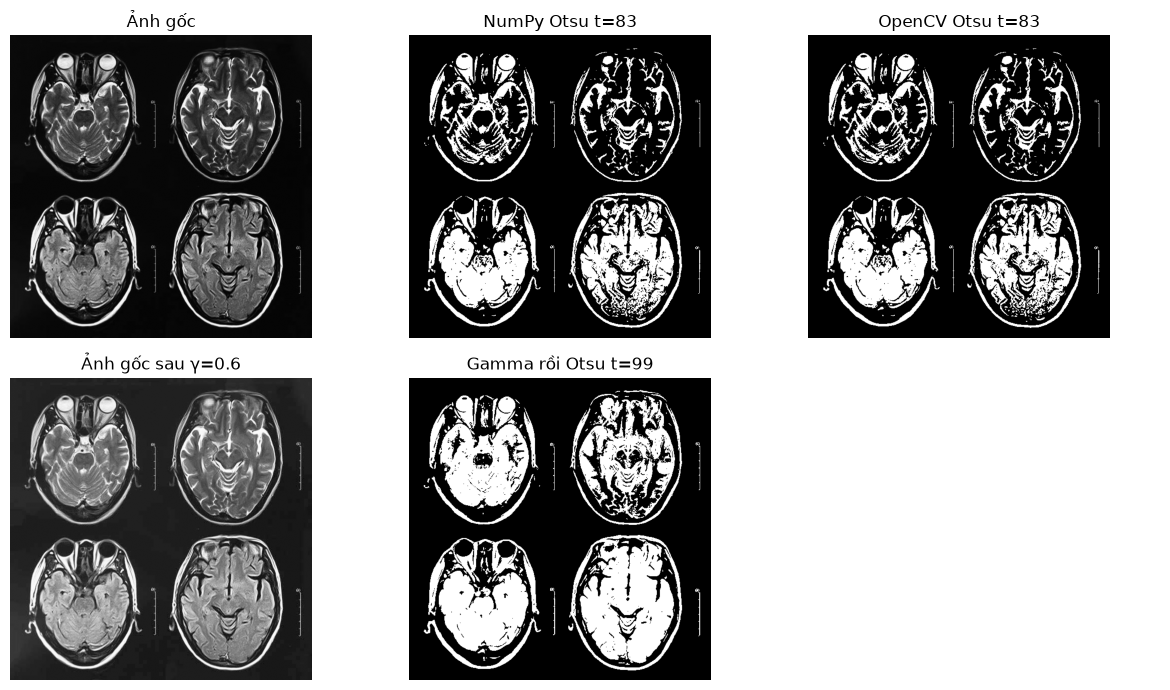

**Nhận xét:** Otsu chọn t=83 bằng NumPy và t=83 bằng OpenCV. Mask giống nhau 99.70%; sai khác ở pixel đúng ngưỡng vì NumPy dùng >=t còn OpenCV dùng >t. Sau gamma 0.6, t=99 và mask tiền cảnh chiếm 32.8% (trước gamma 22.4%). Gamma thay đổi histogram nên có thể giúp hoặc làm khó phân tách. Otsu hợp với histogram gần hai đỉnh/ánh sáng đều; bóng, lớp cường độ chồng lấn hoặc đối tượng quá nhỏ dễ làm ngưỡng toàn cục kém hiệu quả.

In [5]:
def otsu_numpy(image):
    hist = np.bincount(image.ravel(), minlength=256).astype(np.float64)
    total = hist.sum()
    if total == 0:
        return 0, np.zeros_like(image)
    probability = hist / total
    weight0 = np.cumsum(probability)
    mean0_acc = np.cumsum(probability * np.arange(256))
    mean_total = mean0_acc[-1]
    weight1 = 1.0 - weight0
    mean0 = mean0_acc / (weight0 + 1e-12)
    mean1 = (mean_total - mean0_acc) / (weight1 + 1e-12)
    variance_between = weight0 * weight1 * (mean0 - mean1) ** 2
    threshold = int(np.argmax(variance_between))
    binary = np.where(image >= threshold, 255, 0).astype(np.uint8)
    return threshold, binary


def otsu_opencv(image):
    threshold, binary = cv2.threshold(
        image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    return int(threshold), binary


otsu_image = read_gray("threshold_ostu1.jpg")
otsu_threshold_np, otsu_mask_np = otsu_numpy(otsu_image)
otsu_threshold_cv, otsu_mask_cv = otsu_opencv(otsu_image)
gamma_otsu_image = gamma_numpy(otsu_image, 0.6)
gamma_otsu_threshold, gamma_otsu_mask = otsu_numpy(gamma_otsu_image)
compare_images(
    [otsu_image, otsu_mask_np, otsu_mask_cv, gamma_otsu_image, gamma_otsu_mask],
    ["Ảnh gốc", f"NumPy Otsu t={otsu_threshold_np}", f"OpenCV Otsu t={otsu_threshold_cv}",
     "Ảnh gốc sau γ=0.6", f"Gamma rồi Otsu t={gamma_otsu_threshold}"],
    columns=3,
)
display(Markdown(
    f"**Nhận xét:** Otsu chọn t={otsu_threshold_np} bằng NumPy và t={otsu_threshold_cv} bằng OpenCV. "
    f"Mask giống nhau {np.mean(otsu_mask_np == otsu_mask_cv)*100:.2f}%; sai khác ở pixel đúng ngưỡng vì NumPy dùng >=t còn OpenCV dùng >t. "
    f"Sau gamma 0.6, t={gamma_otsu_threshold} và mask tiền cảnh chiếm {np.mean(gamma_otsu_mask > 0)*100:.1f}% (trước gamma {np.mean(otsu_mask_np > 0)*100:.1f}%). "
    "Gamma thay đổi histogram nên có thể giúp hoặc làm khó phân tách. Otsu hợp với histogram gần hai đỉnh/ánh sáng đều; bóng, lớp cường độ chồng lấn hoặc đối tượng quá nhỏ dễ làm ngưỡng toàn cục kém hiệu quả."
))

## 5. Pipeline tích hợp Part 1

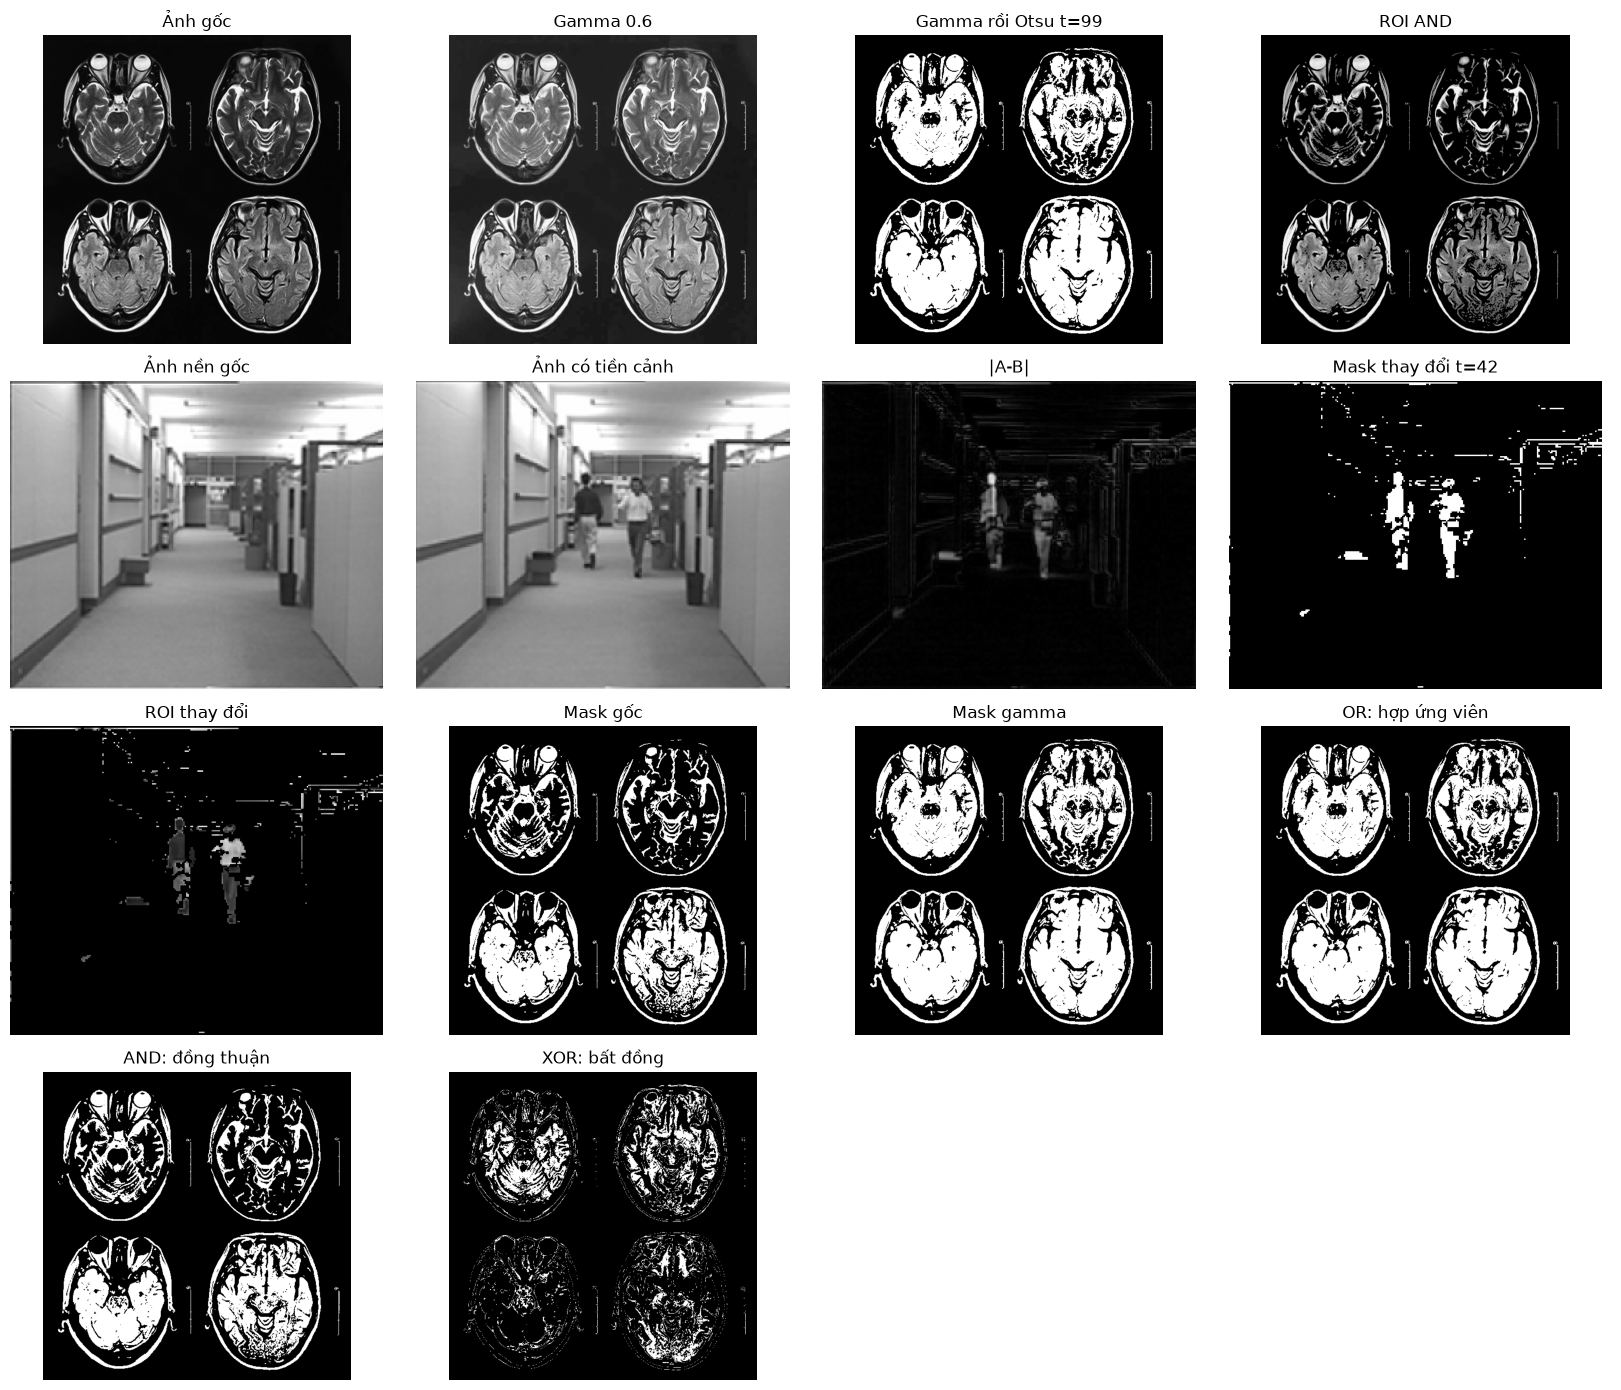

**Nhận xét:** Cặp nền/tiền cảnh cùng kích thước 263×217 cho thấy người mới xuất hiện trong ảnh sai khác; Otsu chọn t=42. Mask đổi sáng chiếm 3.8% ảnh. OR giữ ứng viên ở một trong hai mask, AND giữ phần đồng thuận, XOR giữ phần bất đồng.

In [6]:
# Làm sáng rồi Otsu
bright_image = gamma_numpy(otsu_image, 0.6)
bright_threshold, bright_mask = otsu_numpy(bright_image)

# Trích ROI bằng AND
otsu_roi = cv2.bitwise_and(otsu_image, otsu_image, mask=otsu_mask_np)

# Phát hiện thay đổi trên cặp ảnh đã căn chỉnh
background = read_gray("1_background.png")
foreground = read_gray("2_Background_foreground.png")
assert background.shape == foreground.shape
absolute_difference = cv2.absdiff(background, foreground)
change_threshold, change_mask = otsu_numpy(absolute_difference)
change_roi = cv2.bitwise_and(foreground, foreground, mask=change_mask)

# Hợp nhất mask từ ảnh gốc và ảnh sau gamma
mask_original = np.where(otsu_image >= otsu_threshold_np, 255, 0).astype(np.uint8)
mask_gamma = np.where(bright_image >= bright_threshold, 255, 0).astype(np.uint8)
mask_or = cv2.bitwise_or(mask_original, mask_gamma)
mask_and = cv2.bitwise_and(mask_original, mask_gamma)
mask_xor = cv2.bitwise_xor(mask_original, mask_gamma)

compare_images(
    [otsu_image, bright_image, bright_mask, otsu_roi,
     background, foreground, absolute_difference, change_mask, change_roi,
     mask_original, mask_gamma, mask_or, mask_and, mask_xor],
    ["Ảnh gốc", "Gamma 0.6", f"Gamma rồi Otsu t={bright_threshold}", "ROI AND",
     "Ảnh nền gốc", "Ảnh có tiền cảnh", "|A-B|", f"Mask thay đổi t={change_threshold}", "ROI thay đổi",
     "Mask gốc", "Mask gamma", "OR: hợp ứng viên", "AND: đồng thuận", "XOR: bất đồng"],
    columns=4,
)
display(Markdown(
    f"**Nhận xét:** Cặp nền/tiền cảnh cùng kích thước {background.shape[1]}×{background.shape[0]} cho thấy người mới xuất hiện trong ảnh sai khác; Otsu chọn t={change_threshold}. "
    f"Mask đổi sáng chiếm {np.mean(change_mask > 0)*100:.1f}% ảnh. OR giữ ứng viên ở một trong hai mask, AND giữ phần đồng thuận, XOR giữ phần bất đồng."
))

## 6. Tích chập 2D

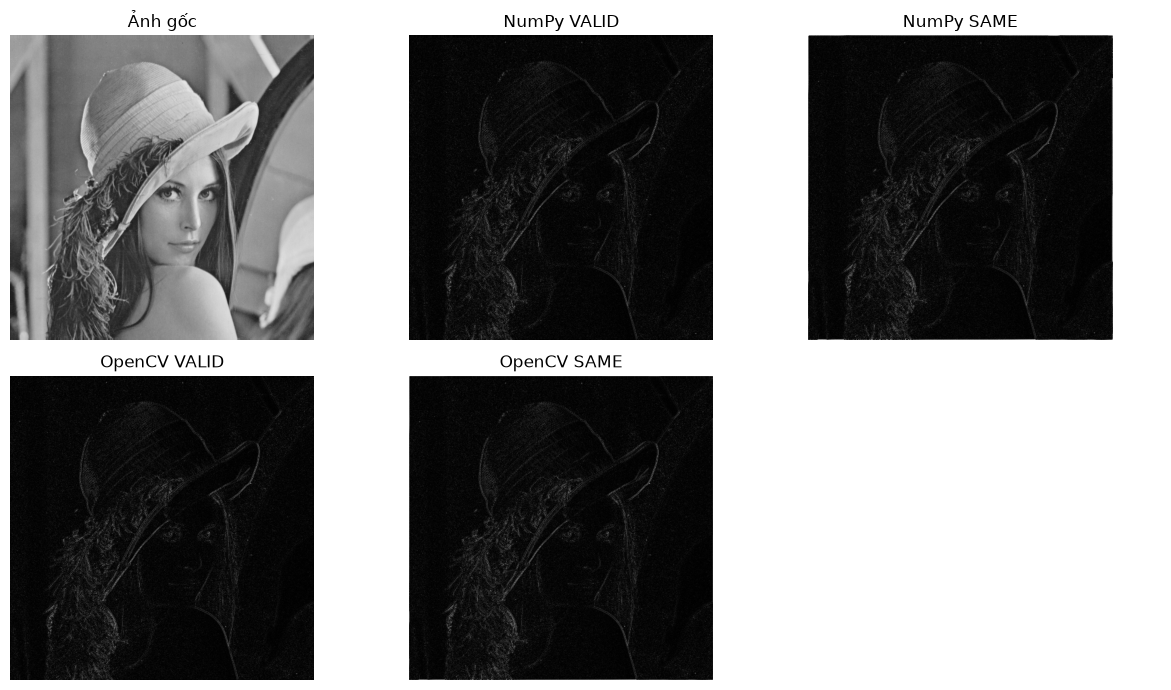

**Nhận xét:** Kernel Laplacian làm nổi biên. VALID cho kích thước 510×510, SAME giữ 512×512. Sai khác tuyệt đối trung bình NumPy/OpenCV: VALID 0.000000, SAME 0.000000. Phản hồi có thể âm/vượt 255; hình dùng trị tuyệt đối và chung một hệ số chuẩn hóa để so sánh với ảnh gốc. PDF chỉ nêu convolution trong mục tiêu, không có đề chi tiết riêng cho phần này.

In [7]:
def convolve_numpy(image, kernel, mode):
    image = image.astype(np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    if kernel.ndim != 2 or any(size % 2 == 0 for size in kernel.shape):
        raise ValueError("Kernel phải là ma trận 2D kích thước lẻ")
    py, px = kernel.shape[0] // 2, kernel.shape[1] // 2
    if mode.upper() == "SAME":
        image = np.pad(image, ((py, py), (px, px)), mode="constant")
    elif mode.upper() != "VALID":
        raise ValueError("mode phải là VALID hoặc SAME")
    if image.shape[0] < kernel.shape[0] or image.shape[1] < kernel.shape[1]:
        raise ValueError("Kernel lớn hơn ảnh")
    windows = np.lib.stride_tricks.sliding_window_view(image, kernel.shape)
    return np.einsum("ijkl,kl->ij", windows, kernel[::-1, ::-1], optimize=True)


def response_view(response, scale):
    return np.clip(np.abs(response) / scale * 255 + 0.5, 0, 255).astype(np.uint8)


convolution_image = read_gray("lena.png")
laplacian = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], dtype=np.float32)
conv_valid_np = convolve_numpy(convolution_image, laplacian, "VALID")
conv_same_np = convolve_numpy(convolution_image, laplacian, "SAME")
conv_same_cv = cv2.filter2D(
    convolution_image.astype(np.float32), cv2.CV_32F, laplacian,
    borderType=cv2.BORDER_CONSTANT,
)
conv_valid_cv = conv_same_cv[1:-1, 1:-1]
shared_scale = max(np.abs(conv_valid_np).max(), np.abs(conv_same_np).max())
compare_images(
    [convolution_image, response_view(conv_valid_np, shared_scale), response_view(conv_same_np, shared_scale),
     response_view(conv_valid_cv, shared_scale), response_view(conv_same_cv, shared_scale)],
    ["Ảnh gốc", "NumPy VALID", "NumPy SAME", "OpenCV VALID", "OpenCV SAME"],
    columns=3,
)
display(Markdown(
    f"**Nhận xét:** Kernel Laplacian làm nổi biên. VALID cho kích thước {conv_valid_np.shape[1]}×{conv_valid_np.shape[0]}, SAME giữ {conv_same_np.shape[1]}×{conv_same_np.shape[0]}. "
    f"Sai khác tuyệt đối trung bình NumPy/OpenCV: VALID {np.mean(np.abs(conv_valid_np-conv_valid_cv)):.6f}, SAME {np.mean(np.abs(conv_same_np-conv_same_cv)):.6f}. "
    "Phản hồi có thể âm/vượt 255; hình dùng trị tuyệt đối và chung một hệ số chuẩn hóa để so sánh với ảnh gốc. PDF chỉ nêu convolution trong mục tiêu, không có đề chi tiết riêng cho phần này."
))

## 7. Translation

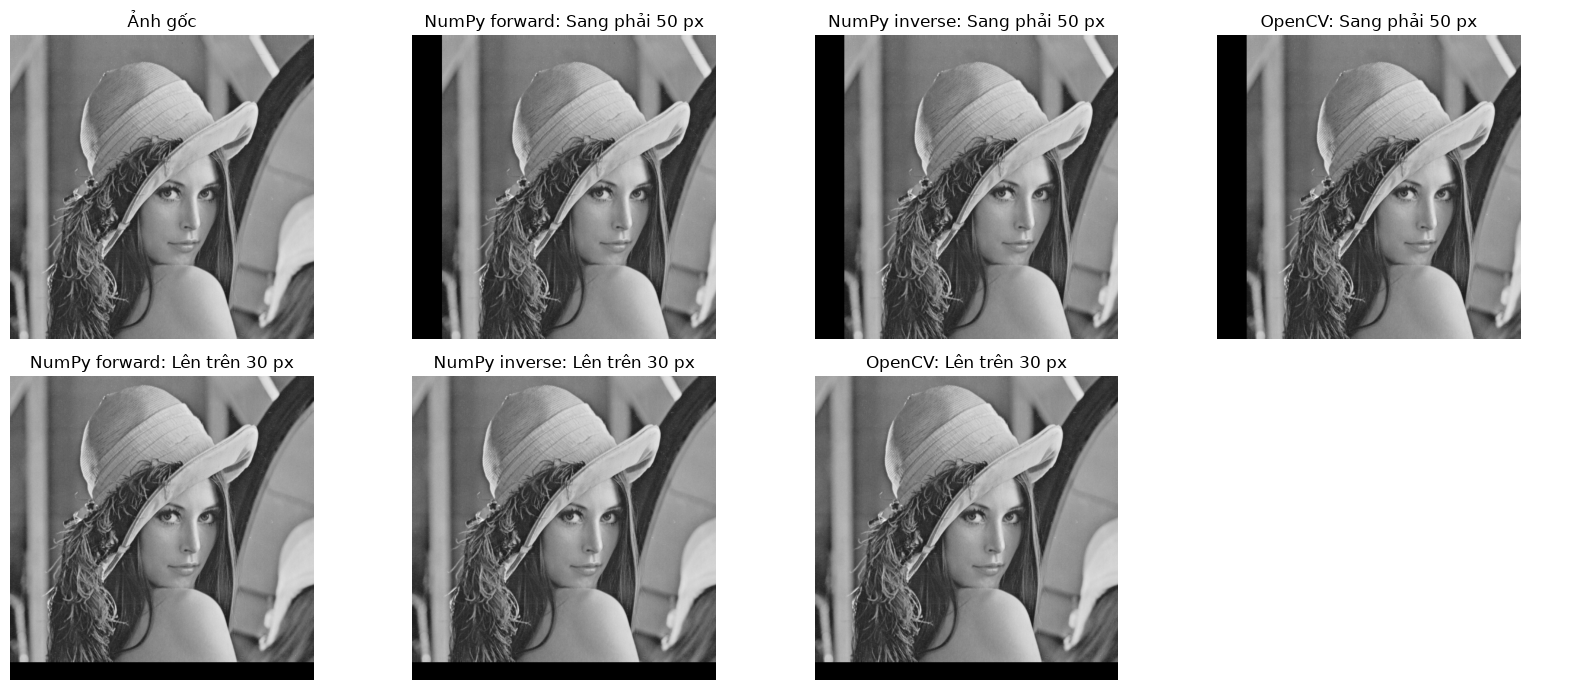

**Nhận xét:** Canvas cố định nên phần vượt biên bị cắt và vùng mới được điền 0. Inverse mapping lấy mẫu nguồn cho từng pixel đích, tránh pixel holes tổng quát; dịch nguyên pixel trong ví dụ này không tạo lỗ.

In [8]:
def translate_forward(image, tx, ty):
    h, w = image.shape
    output = np.zeros_like(image)
    for y in range(h):
        for x in range(w):
            nx, ny = x + tx, y + ty
            if 0 <= nx < w and 0 <= ny < h:
                output[ny, nx] = image[y, x]
    return output


def translate_inverse(image, tx, ty):
    h, w = image.shape
    output = np.zeros_like(image)
    for y in range(h):
        for x in range(w):
            sx, sy = x - tx, y - ty
            if 0 <= sx < w and 0 <= sy < h:
                output[y, x] = image[sy, sx]
    return output


translation_image = read_gray("lena.png")
translation_results = [translation_image]
translation_titles = ["Ảnh gốc"]
for tx, ty, label in ((50, 0, "Sang phải 50 px"), (0, -30, "Lên trên 30 px")):
    numpy_forward = translate_forward(translation_image, tx, ty)
    numpy_inverse = translate_inverse(translation_image, tx, ty)
    matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    cv_result = cv2.warpAffine(
        translation_image, matrix, (translation_image.shape[1], translation_image.shape[0]),
        flags=cv2.INTER_NEAREST, borderValue=0,
    )
    translation_results.extend([numpy_forward, numpy_inverse, cv_result])
    translation_titles.extend([f"NumPy forward: {label}", f"NumPy inverse: {label}", f"OpenCV: {label}"])
compare_images(translation_results, translation_titles, columns=4)
display(Markdown(
    "**Nhận xét:** Canvas cố định nên phần vượt biên bị cắt và vùng mới được điền 0. Inverse mapping lấy mẫu nguồn cho từng pixel đích, tránh pixel holes tổng quát; dịch nguyên pixel trong ví dụ này không tạo lỗ."
))

## 8. Scaling

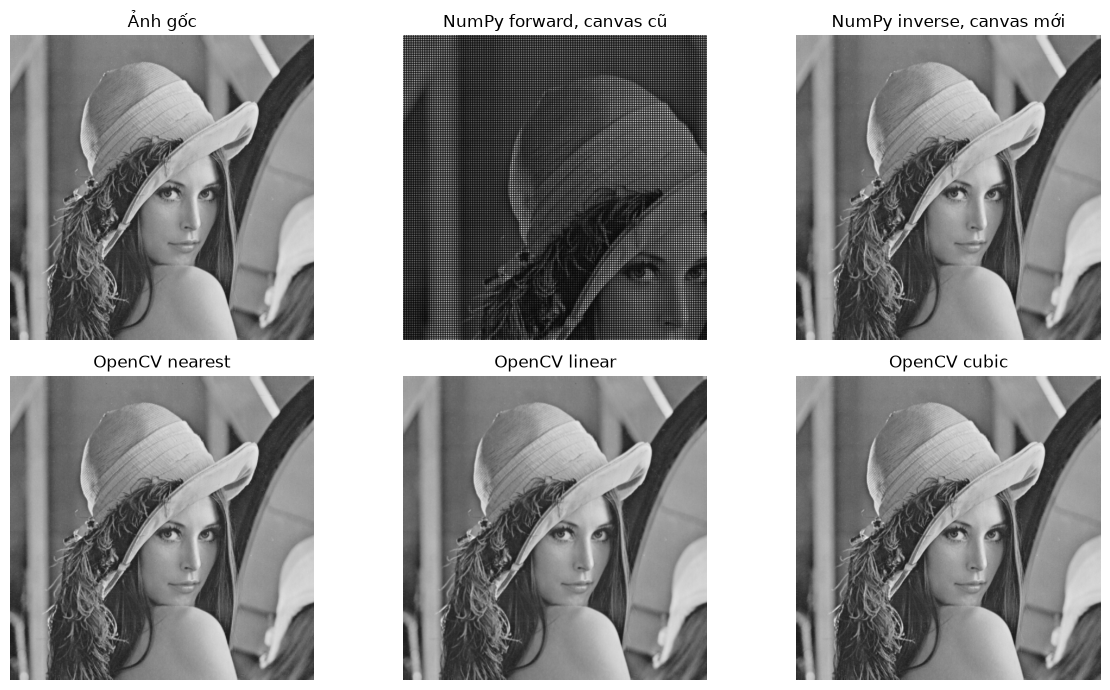

**Nhận xét:** Ảnh gốc 512×512; canvas 1.5× là 768×768. NumPy inverse và OpenCV nearest giống nhau 100.0% pixel. Linear/cubic nội suy mượt hơn nearest khi phóng ảnh; canvas giữ nguyên kích thước sẽ crop và bỏ nhiều pixel đích.

In [9]:
def scale_forward(image, sx, sy):
    h, w = image.shape
    output = np.zeros_like(image)
    for y in range(h):
        for x in range(w):
            nx, ny = int(x * sx), int(y * sy)
            if 0 <= nx < w and 0 <= ny < h:
                output[ny, nx] = image[y, x]
    return output


def scale_canvas(image, sx, sy):
    h, w = image.shape
    new_w, new_h = int(w * sx), int(h * sy)
    output = np.zeros((new_h, new_w), dtype=image.dtype)
    for y in range(new_h):
        for x in range(new_w):
            sx0, sy0 = int(x / sx), int(y / sy)
            if sx0 < w and sy0 < h:
                output[y, x] = image[sy0, sx0]
    return output


scaling_image = read_gray("lena.png")
scale_forward_result = scale_forward(scaling_image, 1.5, 1.5)
scale_inverse_result = scale_canvas(scaling_image, 1.5, 1.5)
scale_nearest = cv2.resize(scaling_image, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_NEAREST)
scale_linear = cv2.resize(scaling_image, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_LINEAR)
scale_cubic = cv2.resize(scaling_image, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
compare_images(
    [scaling_image, scale_forward_result, scale_inverse_result, scale_nearest, scale_linear, scale_cubic],
    ["Ảnh gốc", "NumPy forward, canvas cũ", "NumPy inverse, canvas mới",
     "OpenCV nearest", "OpenCV linear", "OpenCV cubic"],
    columns=3,
)
display(Markdown(
    f"**Nhận xét:** Ảnh gốc {scaling_image.shape[1]}×{scaling_image.shape[0]}; canvas 1.5× là {scale_inverse_result.shape[1]}×{scale_inverse_result.shape[0]}. "
    f"NumPy inverse và OpenCV nearest giống nhau {np.mean(scale_inverse_result == scale_nearest)*100:.1f}% pixel. "
    "Linear/cubic nội suy mượt hơn nearest khi phóng ảnh; canvas giữ nguyên kích thước sẽ crop và bỏ nhiều pixel đích."
))

## 9. Rotation

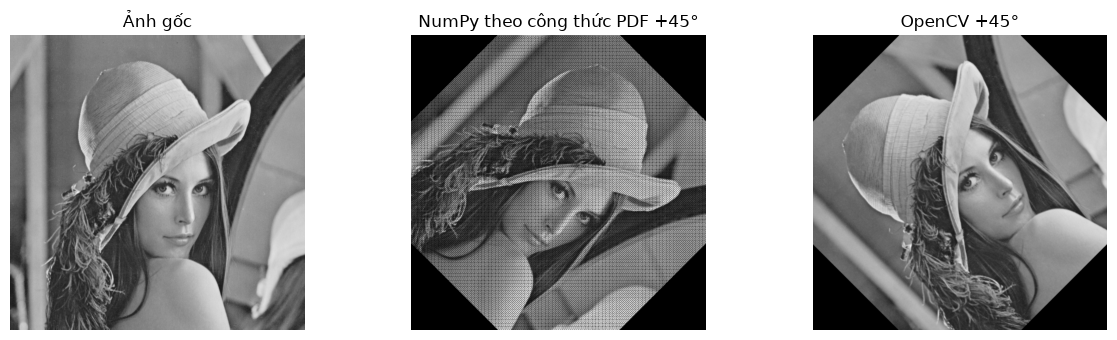

**Nhận xét:** Cùng canvas nên các góc bị crop; forward mapping để lại vị trí chưa được ghi. Công thức PDF dùng y hướng xuống nên góc +45° có hướng nhìn ngược với quy ước góc của getRotationMatrix2D; warpAffine còn nội suy pixel đích.

In [10]:
def rotate_forward(image, angle):
    h, w = image.shape
    cx, cy = w // 2, h // 2
    rad = np.radians(angle)
    cosine, sine = np.cos(rad), np.sin(rad)
    output = np.zeros_like(image)
    for y in range(h):
        for x in range(w):
            x0, y0 = x - cx, y - cy
            nx = int(cosine * x0 - sine * y0 + cx)
            ny = int(sine * x0 + cosine * y0 + cy)
            if 0 <= nx < w and 0 <= ny < h:
                output[ny, nx] = image[y, x]
    return output


rotation_image = read_gray("lena.png")
rotation_numpy = rotate_forward(rotation_image, 45)
h, w = rotation_image.shape
rotation_matrix_cv = cv2.getRotationMatrix2D((w // 2, h // 2), 45, 1.0)
rotation_cv = cv2.warpAffine(rotation_image, rotation_matrix_cv, (w, h), borderValue=0)
compare_images(
    [rotation_image, rotation_numpy, rotation_cv],
    ["Ảnh gốc", "NumPy theo công thức PDF +45°", "OpenCV +45°"],
    columns=3,
)
display(Markdown(
    "**Nhận xét:** Cùng canvas nên các góc bị crop; forward mapping để lại vị trí chưa được ghi. Công thức PDF dùng y hướng xuống nên góc +45° có hướng nhìn ngược với quy ước góc của getRotationMatrix2D; warpAffine còn nội suy pixel đích."
))

## 10. Skew / Shear

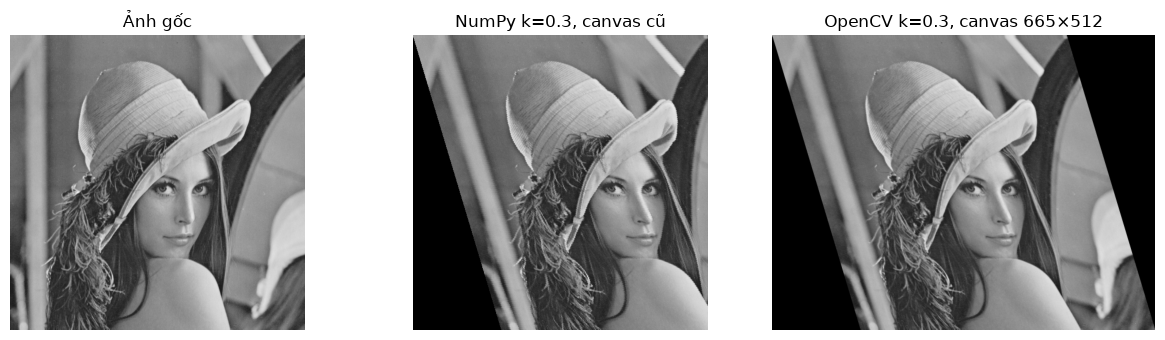

**Nhận xét:** Shear dịch ngang theo y. Canvas NumPy giữ rộng 512px nên crop phần bên phải; OpenCV mở rộng canvas theo ví dụ PDF để giữ phần ảnh vượt biên.

In [11]:
def shear_forward(image, k):
    h, w = image.shape
    output = np.zeros_like(image)
    for y in range(h):
        for x in range(w):
            nx = int(x + k * y)
            if 0 <= nx < w:
                output[y, nx] = image[y, x]
    return output


shear_image = read_gray("lena.png")
shear_numpy = shear_forward(shear_image, 0.3)
h, w = shear_image.shape
shear_matrix = np.float32([[1, 0.3, 0], [0, 1, 0]])
new_width = int(w + abs(0.3 * h))
shear_cv = cv2.warpAffine(shear_image, shear_matrix, (new_width, h), borderValue=0)
compare_images(
    [shear_image, shear_numpy, shear_cv],
    ["Ảnh gốc", "NumPy k=0.3, canvas cũ", f"OpenCV k=0.3, canvas {new_width}×{h}"],
    columns=3,
)
display(Markdown(
    f"**Nhận xét:** Shear dịch ngang theo y. Canvas NumPy giữ rộng {w}px nên crop phần bên phải; OpenCV mở rộng canvas theo ví dụ PDF để giữ phần ảnh vượt biên."
))

## 11. Ghép phép biến đổi affine và đo tốc độ

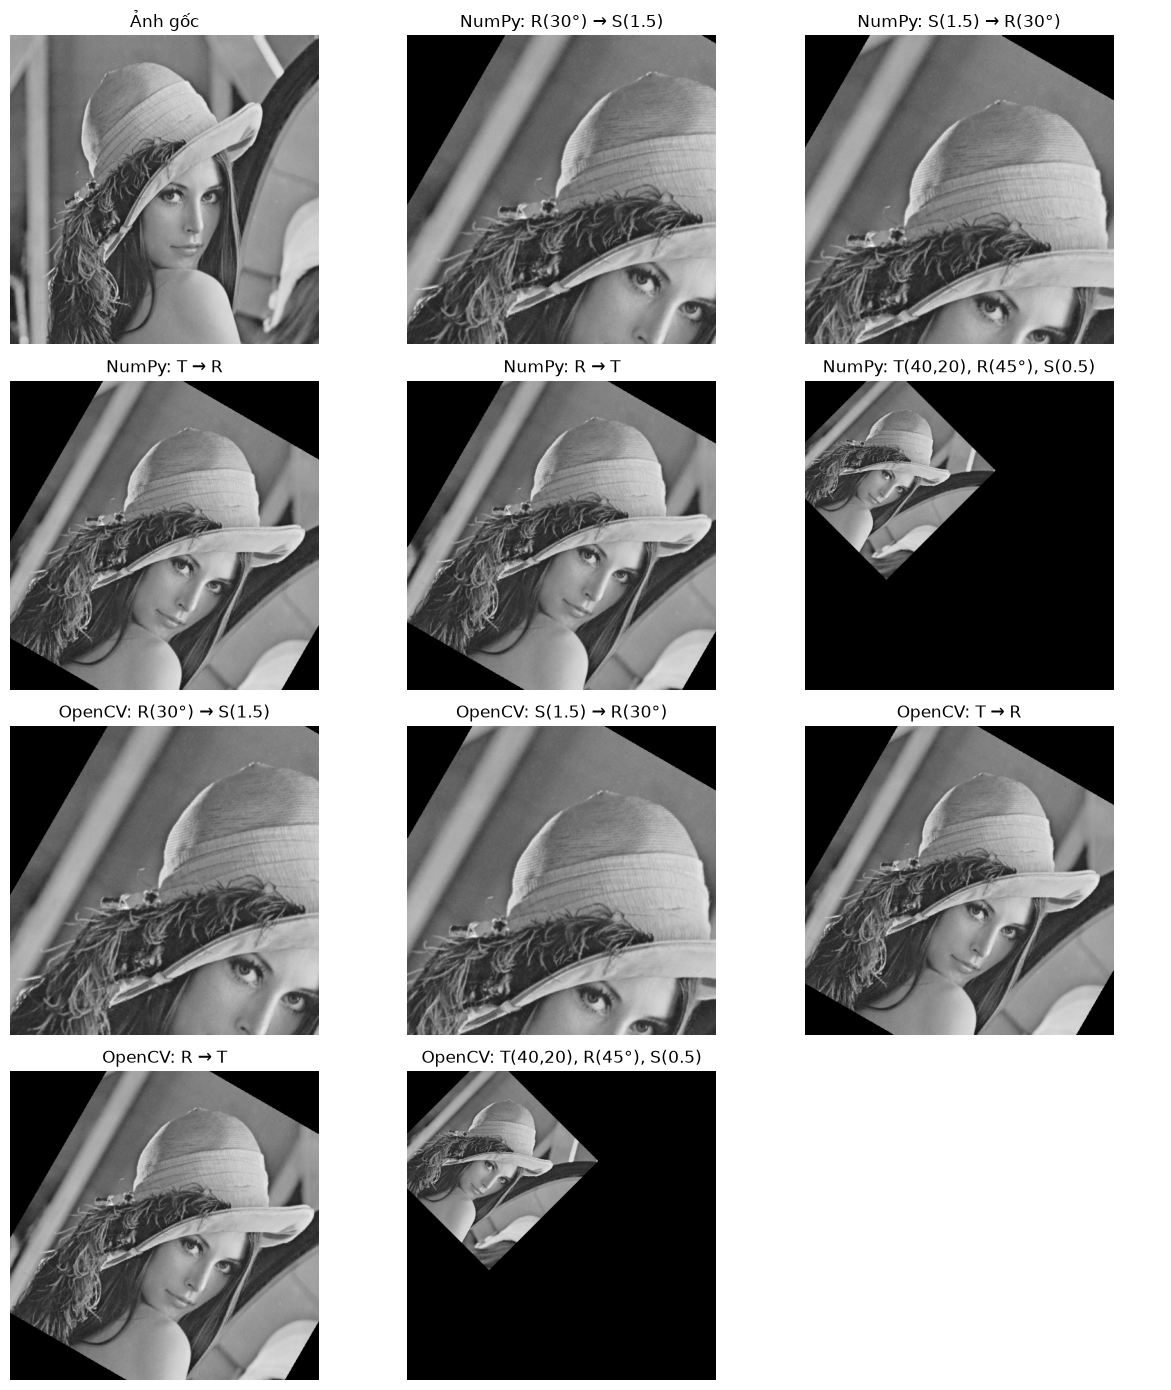

R(30°) → S(1.5): NumPy/OpenCV giống nhau 100.00% pixel
S(1.5) → R(30°): NumPy/OpenCV giống nhau 100.00% pixel
T → R: NumPy/OpenCV giống nhau 99.98% pixel
R → T: NumPy/OpenCV giống nhau 99.94% pixel
T(40,20), R(45°), S(0.5): NumPy/OpenCV giống nhau 100.00% pixel


**Nhận xét:** Đổi thứ tự phép quay và scale cho kết quả khác vì scale neo ở gốc còn rotation quanh tâm ảnh; T→R khác R→T vì vector tịnh tiến cũng bị quay. So sánh tốc độ tốt nhất trong 5 lần đo trên 512×512: NumPy 16.58 ms, OpenCV 0.06 ms. Đây là số đo trên máy hiện tại; phép affine dùng cùng ma trận/canvas và nearest để đối chiếu.

In [12]:
def translation_matrix(tx, ty):
    return np.array([[1., 0., tx], [0., 1., ty], [0., 0., 1.]])


def rotation_matrix(degrees):
    angle = np.radians(degrees)
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, 0.], [s, c, 0.], [0., 0., 1.]])


def centered_matrix(linear, cx, cy):
    return translation_matrix(cx, cy) @ linear @ translation_matrix(-cx, -cy)


def scaling_matrix(sx, sy):
    return np.array([[sx, 0., 0.], [0., sy, 0.], [0., 0., 1.]])


def compose_in_order(*matrices):
    combined = np.eye(3)
    for matrix in matrices:
        combined = matrix @ combined
    return combined


def affine_transform(image, matrix):
    h, w = image.shape
    dy, dx = np.indices((h, w), dtype=np.float64)
    destination = np.stack([dx.ravel(), dy.ravel(), np.ones(h * w)])
    source = np.linalg.inv(matrix) @ destination
    sx = np.rint(source[0]).astype(np.int32)
    sy = np.rint(source[1]).astype(np.int32)
    valid = (sx >= 0) & (sx < w) & (sy >= 0) & (sy < h)
    output = np.zeros(h * w, dtype=image.dtype)
    output[valid] = image[sy[valid], sx[valid]]
    return output.reshape(h, w)


affine_image = read_gray("lena.png")
h, w = affine_image.shape
cx, cy = w / 2, h / 2
rotate_30 = centered_matrix(rotation_matrix(30), cx, cy)
scale_15 = scaling_matrix(1.5, 1.5)
translate_40_20 = translation_matrix(40, 20)
matrices = [
    compose_in_order(rotate_30, scale_15),
    compose_in_order(scale_15, rotate_30),
    compose_in_order(translate_40_20, rotate_30),
    compose_in_order(rotate_30, translate_40_20),
    compose_in_order(translate_40_20, centered_matrix(rotation_matrix(45), cx, cy), scaling_matrix(0.5, 0.5)),
]
labels = ["R(30°) → S(1.5)", "S(1.5) → R(30°)", "T → R", "R → T", "T(40,20), R(45°), S(0.5)"]
numpy_affines = [affine_transform(affine_image, matrix) for matrix in matrices]
opencv_affines = [
    cv2.warpAffine(affine_image, matrix[:2].astype(np.float32), (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
    for matrix in matrices
]
compare_images(
    [affine_image, *numpy_affines, *opencv_affines],
    ["Ảnh gốc", *[f"NumPy: {label}" for label in labels], *[f"OpenCV: {label}" for label in labels]],
    columns=3,
)
for label, result_np, result_cv in zip(labels, numpy_affines, opencv_affines):
    print(f"{label}: NumPy/OpenCV giống nhau {np.mean(result_np == result_cv)*100:.2f}% pixel")

repeat_count = 5
numpy_seconds = min(timeit.repeat(lambda: affine_transform(affine_image, matrices[-1]), number=1, repeat=repeat_count))
opencv_seconds = min(timeit.repeat(
    lambda: cv2.warpAffine(affine_image, matrices[-1][:2].astype(np.float32), (w, h), flags=cv2.INTER_NEAREST),
    number=1, repeat=repeat_count,
))
display(Markdown(
    "**Nhận xét:** Đổi thứ tự phép quay và scale cho kết quả khác vì scale neo ở gốc còn rotation quanh tâm ảnh; T→R khác R→T vì vector tịnh tiến cũng bị quay. "
    f"So sánh tốc độ tốt nhất trong {repeat_count} lần đo trên {w}×{h}: NumPy {numpy_seconds*1000:.2f} ms, OpenCV {opencv_seconds*1000:.2f} ms. "
    "Đây là số đo trên máy hiện tại; phép affine dùng cùng ma trận/canvas và nearest để đối chiếu."
))